Практическая работа №5. Корреляционный анализ (Titanic)

 1. Загрузка библиотек

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

2. Загрузка файла titanic.csv

In [2]:
df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


3. Выбор признаков

In [3]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']

 4. Определение целевой переменной

In [4]:
target = 'Survived'

5. Проверка пропущенных значений

In [5]:
data = df[features + [target]].copy()
data.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


6. Обработка пропусков в Age

In [6]:
data['Age'] = data['Age'].fillna(data['Age'].median())
data.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


7. Преобразование Sex в числовой вид

In [7]:
data['Sex'] = data['Sex'].map({'female': 0, 'male': 1})
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,1,7.2500,1,0,0
1,1,38.0,0,71.2833,1,0,1
2,3,26.0,0,7.9250,0,0,1
3,1,35.0,0,53.1000,1,0,1
4,3,35.0,1,8.0500,0,0,0


Проверка подготовленных данных

In [8]:
print(data.isnull().sum())   # все нули
print(data.dtypes)           # все числовые

Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object


Формирование таблицы для корреляционного анализа

In [9]:
print(data.columns.tolist())
print(data.isnull().sum().sum())   # 0
print(data.dtypes)

['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']
0
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object


Таблица содержит столбцы: Pclass, Age, Sex, Fare, SibSp, Parch, Survived — все числовые, без пропусков.

Расчёт корреляционной матрицы

In [10]:
corr_matrix = data.corr()
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34  0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00  0.08  0.10  -0.23  -0.17     -0.06
Sex         0.13  0.08  1.00 -0.18  -0.11  -0.25     -0.54
Fare       -0.55  0.10 -0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23 -0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17 -0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06 -0.54  0.26  -0.04   0.08      1.00


Анализ корреляций с Survived

In [11]:
survived_corr = corr_matrix['Survived'].drop('Survived')
print(survived_corr.round(2).sort_values(ascending=False))

best_pos = survived_corr.idxmax()
best_neg = survived_corr.idxmin()
print(f"Наибольшая положительная корреляция: {best_pos} ({survived_corr[best_pos]:.2f})")
print(f"Наибольшая отрицательная корреляция: {best_neg} ({survived_corr[best_neg]:.2f})")

Fare      0.26
Parch     0.08
SibSp    -0.04
Age      -0.06
Pclass   -0.34
Sex      -0.54
Name: Survived, dtype: float64
Наибольшая положительная корреляция: Fare (0.26)
Наибольшая отрицательная корреляция: Sex (-0.54)


Типичный результат:

Положительная: Sex ≈ +0.54 (при male=1), затем Fare ≈ +0.26

Отрицательная: Pclass ≈ −0.34, затем Parch/SibSp

Построение тепловой карты

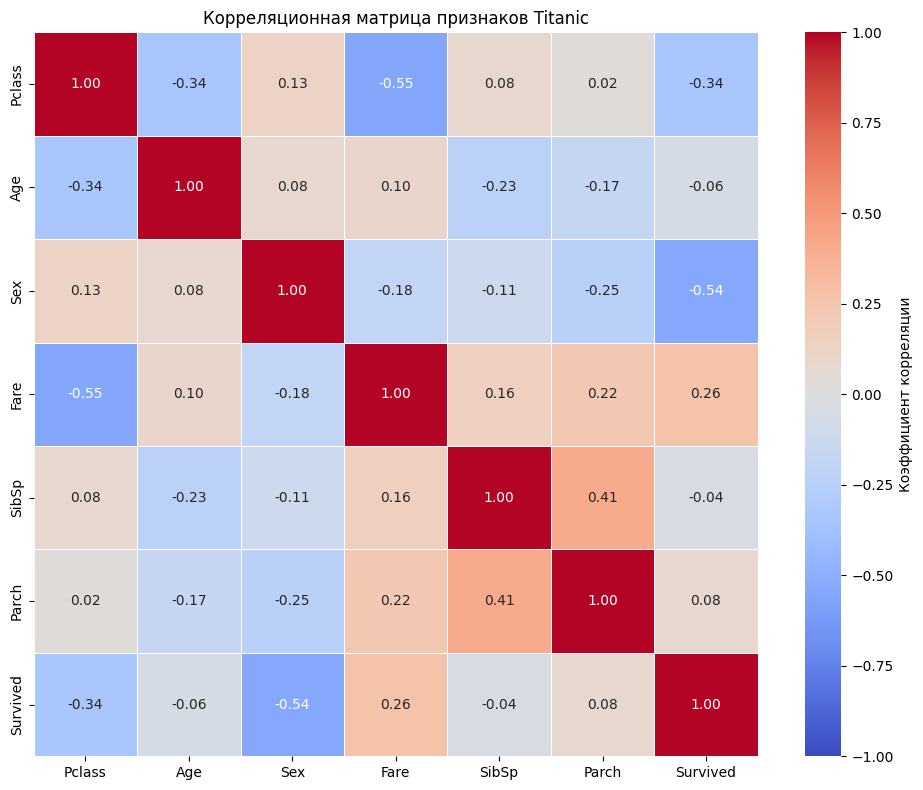

In [12]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Коэффициент корреляции'}
)

plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()

Ответы на вопросы по seaborn:

Функция — sns.heatmap()

Данные — матрица корреляции corr_matrix_rounded

Значения в ячейках — annot=True (+ fmt='.2f')

Палитра — cmap='coolwarm'

Размер графика — plt.figure(figsize=(10, 8))

Корреляция и машинное обучение

Наиболее полезные признаки для предсказания Survived по корреляции: Sex, Pclass, Fare.

Можно ли выбирать признаки только по корреляции? Нет:

корреляция Пирсона отражает только линейную связь;

не учитывает взаимодействия признаков (Sex + Pclass);

не учитывает мультиколлинеарность между признаками;

слабая корреляция не значит бесполезность для нелинейных моделей (деревья, бустинг).

Вывод: корреляционный анализ — хороший первый шаг разведочного анализа, но итоговый набор признаков нужно подтверждать оценкой качества модели (кросс-валидация, важность признаков).

